In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y recursos necesarios se adjunta. Cada actividad necesita un número fijo de operarios y de equipos (grúas, andamios…) durante toda su duración. La empresa dispone como máximo de 4 operarios y 2 equipos en cada semana, **a la vez**.

In [4]:
pregunta_1 = "1. Dibuje las cargas de operarios y de equipos con todas las actividades en su inicio más temprano. ¿En qué semanas se supera cada límite?  "
pregunta_2 = "2. Aplique el algoritmo de asignación comprobando los dos recursos a la vez (una actividad solo empieza si cabe en ambos en todas las semanas que ocuparía). Indique el calendario resultante, la duración del proyecto y, para cada actividad que espera, qué recurso se lo impide.  "
pregunta_3 = "3. Aplique ahora el algoritmo de asignación solo a los operarios, ignorando los equipos, y compruebe qué ocurre con los equipos. ¿Qué enseña esto sobre resolver los recursos de uno en uno?  "
pregunta_4 = "4. ¿Qué recurso es el cuello de botella? Construya la tabla de duración del proyecto al ampliar cada límite hasta dos unidades y recomiende qué ampliar primero.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Dibuje las cargas de operarios y de equipos con todas las actividades en su inicio más temprano. ¿En qué semanas se supera cada límite?  

2. Aplique el algoritmo de asignación comprobando los dos recursos a la vez (una actividad solo empieza si cabe en ambos en todas las semanas que ocuparía). Indique el calendario resultante, la duración del proyecto y, para cada actividad que espera, qué recurso se lo impide.  

3. Aplique ahora el algoritmo de asignación solo a los operarios, ignorando los equipos, y compruebe qué ocurre con los equipos. ¿Qué enseña esto sobre resolver los recursos de uno en uno?  

4. ¿Qué recurso es el cuello de botella? Construya la tabla de duración del proyecto al ampliar cada límite hasta dos unidades y recomiende qué ampliar primero.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, operarios, equipos
    ('A'     , '---'      , 4       , 1        , 0      ),
    ('B'     , '---'      , 3       , 3        , 0      ),
    ('C'     , 'A,B'      , 5       , 1        , 1      ),
    ('D'     , 'A'        , 1       , 2        , 1      ),
    ('E'     , 'C'        , 2       , 1        , 1      ),
    ('F'     , 'C,D'      , 2       , 3        , 2      ),
    ('G'     , 'E'        , 8       , 1        , 0      ),
    ('H'     , 'F'        , 3       , 4        , 2      ),
], columns=['activity', 'predecessor', 'duration', 'operarios', 'equipos']).set_index('activity')
datos_enunciado

,predecessor,duration,operarios,equipos
activity,,,,
A,---,4,1,0
B,---,3,3,0
C,"A,B",5,1,1
D,A,1,2,1
E,C,2,1,1
F,"C,D",2,3,2
G,E,8,1,0
H,F,3,4,2


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_minima = proyecto.duration(datos_proyecto['duration'])
recursos = ['operarios', 'equipos']
limites = [4, 2]

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Dibuje las cargas de operarios y de equipos con todas las actividades en su inicio más temprano. ¿En qué semanas se supera cada límite?  

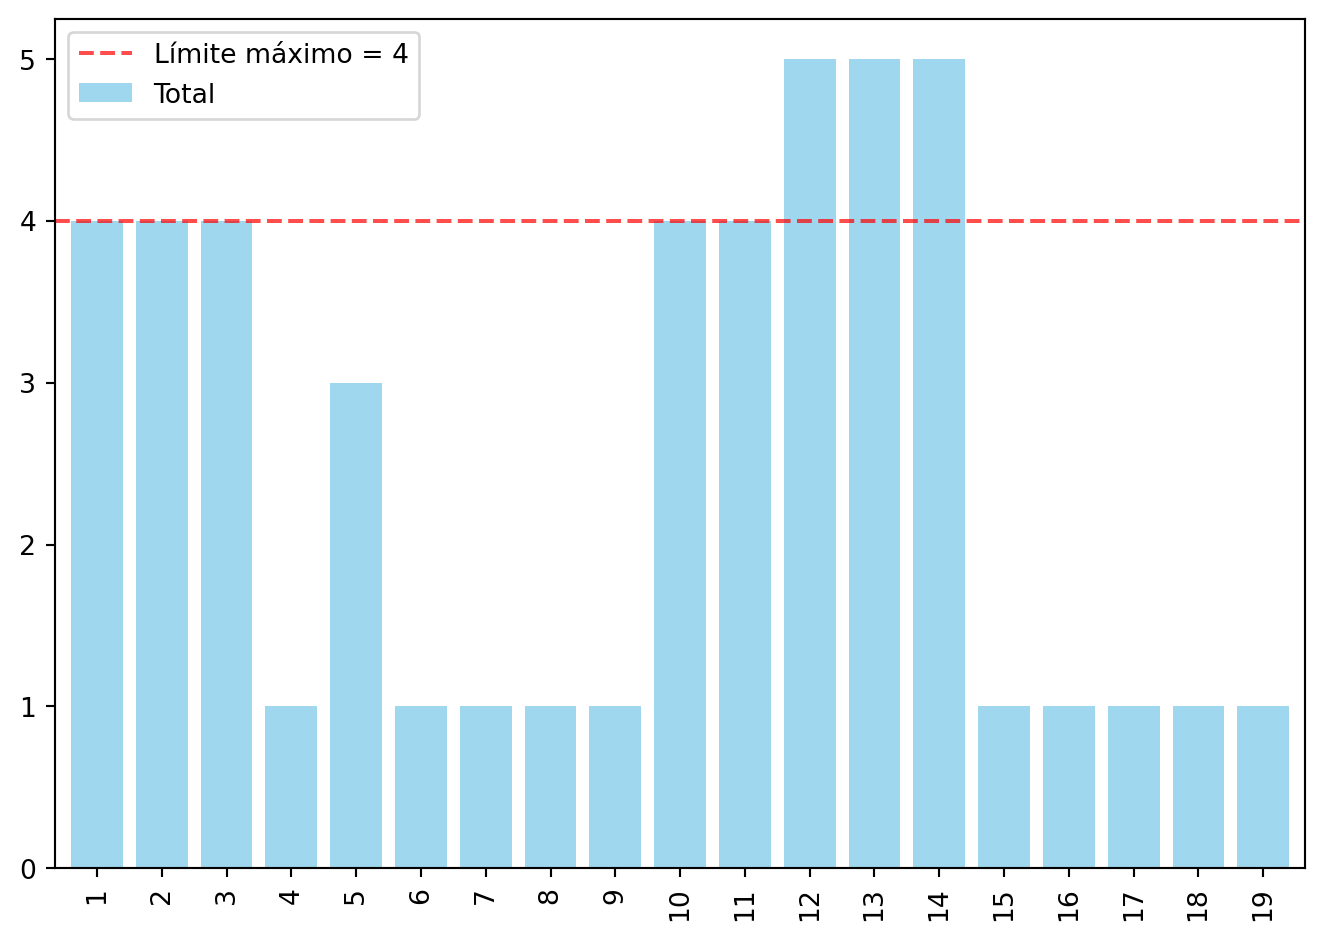

In [8]:
#| fig-cap: "Cargas de operarios con los inicios más tempranos"
#| label: fig-cargasOperarios
gantt_op, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'operarios', report=False, tikz=True, params=GANTT_PARAMS)
plot_cargas(gantt_df=gantt_op, limite_maximo_recursos=limites[0])

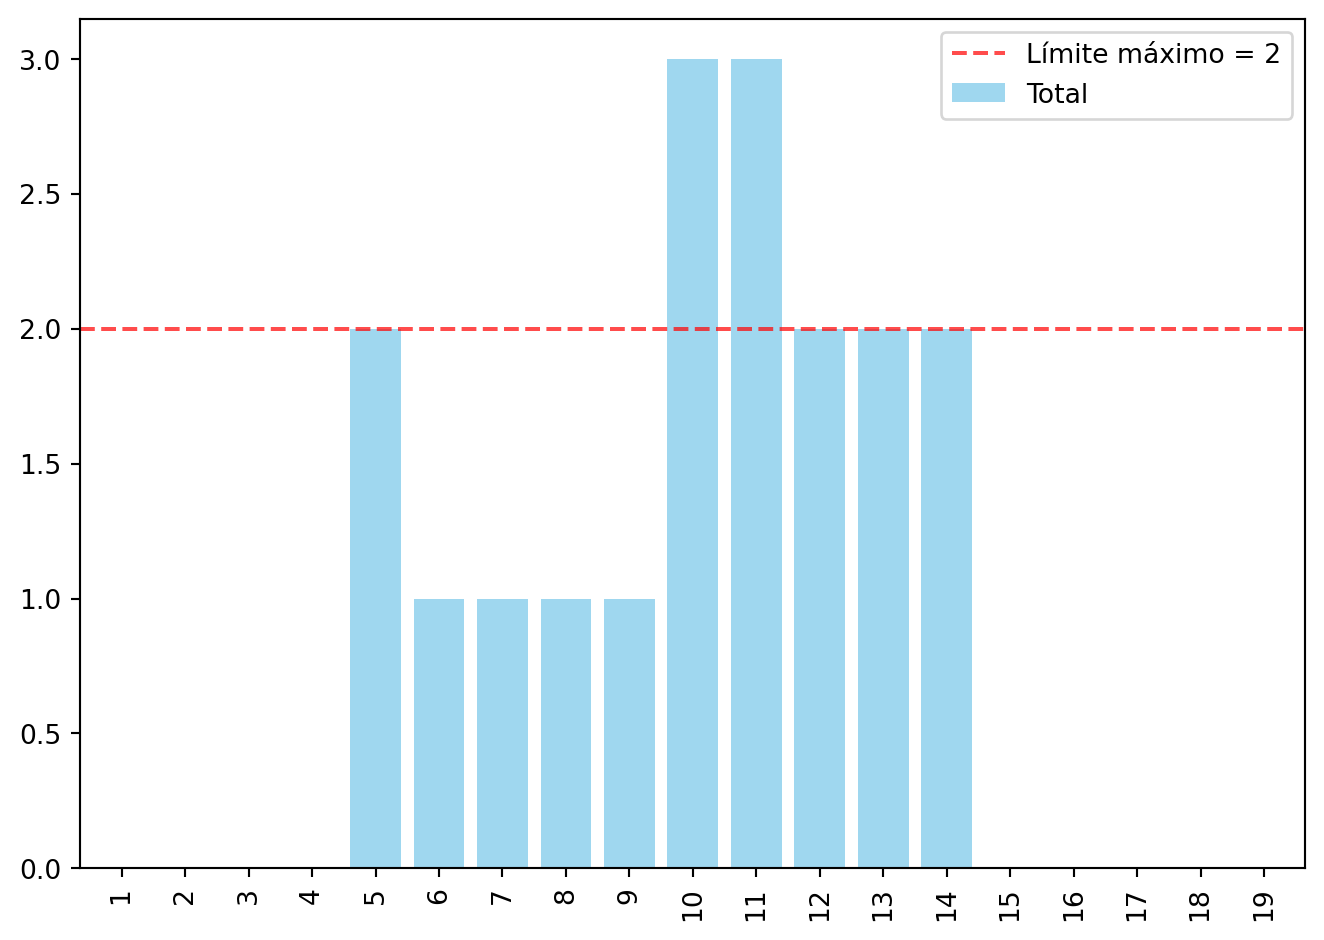

In [9]:
#| fig-cap: "Cargas de equipos con los inicios más tempranos"
#| label: fig-cargasEquipos
gantt_eq, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'equipos', report=False, tikz=True, params=GANTT_PARAMS)
plot_cargas(gantt_df=gantt_eq, limite_maximo_recursos=limites[1])

In [10]:
cargas_op = gantt_op.data.loc['Total'].drop('H_total').astype(float)
cargas_eq = gantt_eq.data.loc['Total'].drop('H_total').astype(float)
exceso_op = [int(t) for t, c in cargas_op.items() if c > limites[0]]
exceso_eq = [int(t) for t, c in cargas_eq.items() if c > limites[1]]
Markdown(f'Operarios (límite {limites[0]}): se supera en las semanas {exceso_op or "ninguna"}. '
         f'Equipos (límite {limites[1]}): se supera en las semanas {exceso_eq or "ninguna"}.')

Operarios (límite 4): se supera en las semanas [12, 13, 14]. Equipos (límite 2): se supera en las semanas [10, 11].

## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. Aplique el algoritmo de asignación comprobando los dos recursos a la vez (una actividad solo empieza si cabe en ambos en todas las semanas que ocuparía). Indique el calendario resultante, la duración del proyecto y, para cada actividad que espera, qué recurso se lo impide.  

In [12]:
resultado = proyecto.copy().asignar_multi(datos_proyecto.copy(), 'duration', recursos, limites)
calendario = pd.DataFrame({'inicio (semana)': resultado.inicios + 1, 'fin (semana)': resultado.fines,
                          'espera (semanas)': resultado.esperas}).fillna(0).astype(int)
calendario

,inicio (semana),fin (semana),espera (semanas)
A,1,4,0
B,1,3,0
C,5,9,0
D,5,5,0
E,10,11,0
F,12,13,2
G,12,19,0
H,20,22,6


In [13]:
esperas = resultado.traza[resultado.traza.decision == 'espera']
esperas = esperas.rename(columns={'bloqueada_por': 'recurso que se satura'})
esperas[['periodo', 'actividad', 'recurso que se satura']].reset_index(drop=True)

,periodo,actividad,recurso que se satura
0,10,F,equipos
1,11,F,equipos
2,14,H,operarios
3,15,H,operarios
4,16,H,operarios
5,17,H,operarios
6,18,H,operarios
7,19,H,operarios


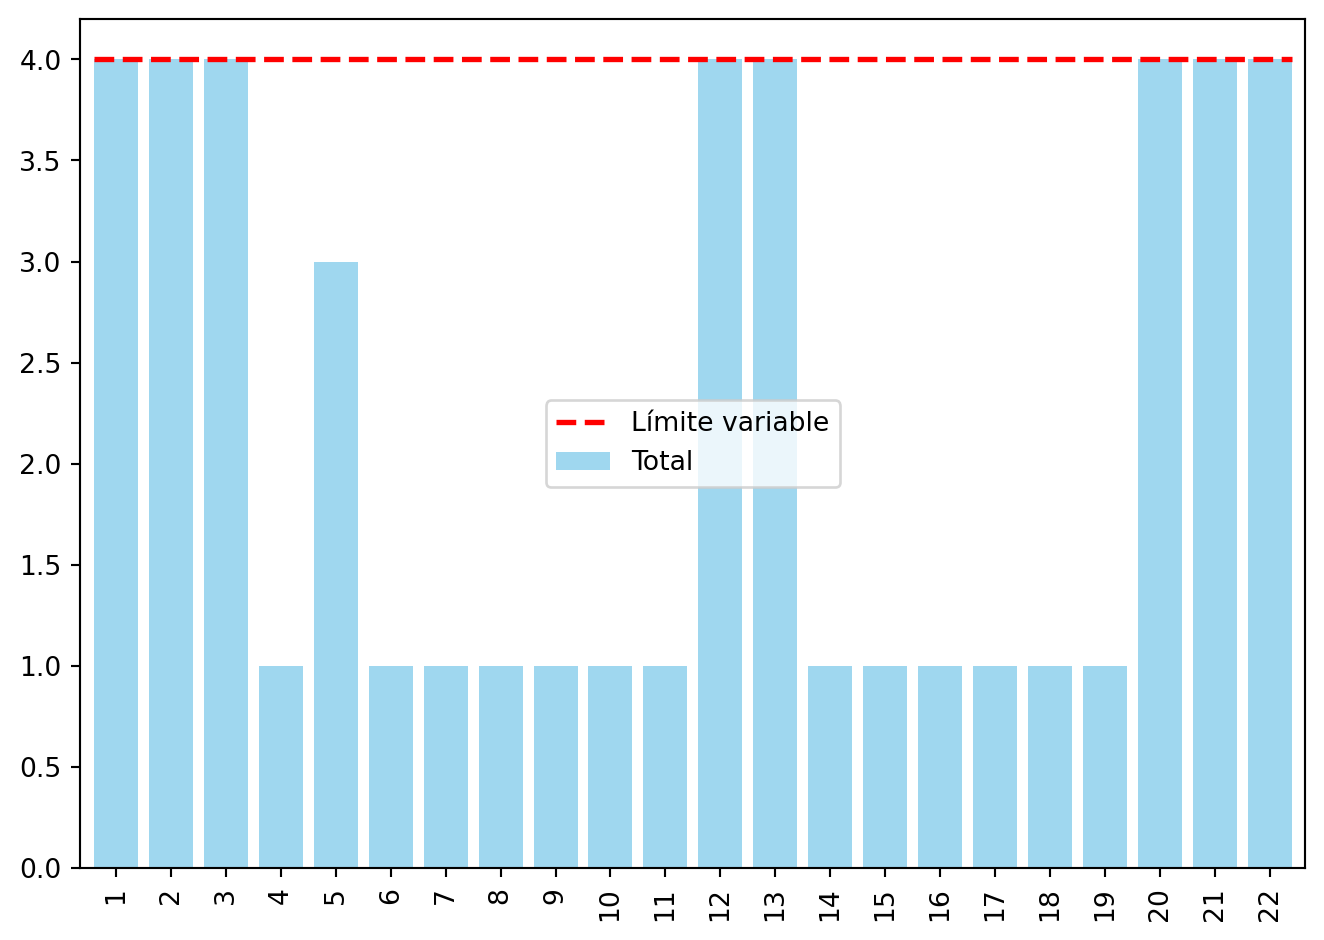

In [14]:
#| fig-cap: "Cargas de operarios tras la asignación simultánea"
#| label: fig-asignacionOperarios
plot_cargas(gantt_df=resultado.gantts['operarios'], limite_maximo_recursos=list(resultado.limites['operarios']))

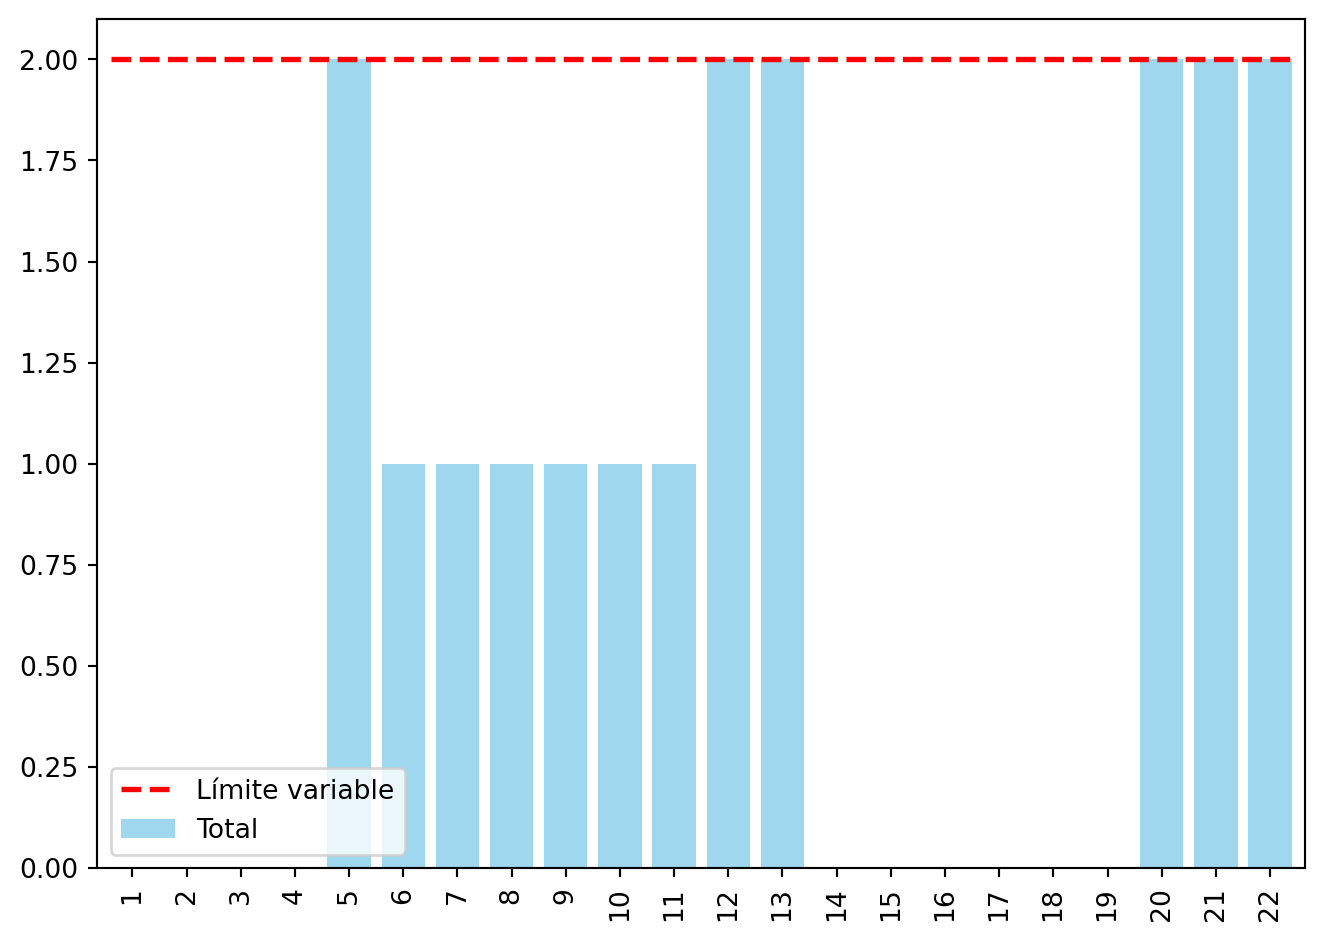

In [15]:
#| fig-cap: "Cargas de equipos tras la asignación simultánea"
#| label: fig-asignacionEquipos
plot_cargas(gantt_df=resultado.gantts['equipos'], limite_maximo_recursos=list(resultado.limites['equipos']))

In [16]:
Markdown(f'La duración pasa de {duracion_minima} a {resultado.duracion} semanas. Cada actividad que espera lo hace '
         'porque, en alguna de las semanas que ocuparía, sumada a lo ya comprometido superaría el límite de '
         'al menos uno de los dos recursos: el que aparece en la tabla.')

La duración pasa de 19 a 22 semanas. Cada actividad que espera lo hace porque, en alguna de las semanas que ocuparía, sumada a lo ya comprometido superaría el límite de al menos uno de los dos recursos: el que aparece en la tabla.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. Aplique ahora el algoritmo de asignación solo a los operarios, ignorando los equipos, y compruebe qué ocurre con los equipos. ¿Qué enseña esto sobre resolver los recursos de uno en uno?  

In [18]:
p_solo = proyecto.copy()
datos_solo, gantt_solo, dibujo = p_solo.asignar(data=datos_proyecto.copy(), duration_label='duration',
                                                resource_label='operarios', maximo=[limites[0]], report=False)
gantt_eq_solo, dibujo = p_solo.gantt_cargas(datos_solo, 'duration', 'equipos', report=False, tikz=False)
cargas_eq_solo = gantt_eq_solo.data.loc['Total'].drop('H_total').astype(float)
exceso = [int(t) for t, c in cargas_eq_solo.items() if c > limites[1]]
Markdown(f'Solo con operarios la duración es {len(gantt_solo.data.columns.drop("H_total"))} semanas, pero los equipos llegan a '
         f'{int(cargas_eq_solo.max())} (límite {limites[1]}) en las semanas {exceso}. '
         'Resolver un recurso desplaza actividades y puede crear picos en el otro: hay que comprobar todos a la vez, '
         'y corregir uno a uno no garantiza converger a un calendario factible.')

Solo con operarios la duración es 22 semanas, pero los equipos llegan a 3 (límite 2) en las semanas [10, 11]. Resolver un recurso desplaza actividades y puede crear picos en el otro: hay que comprobar todos a la vez, y corregir uno a uno no garantiza converger a un calendario factible.

## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. ¿Qué recurso es el cuello de botella? Construya la tabla de duración del proyecto al ampliar cada límite hasta dos unidades y recomiende qué ampliar primero.  

In [20]:
filas = {}
for a in range(3):
    for b in range(3):
        r = proyecto.copy().asignar_multi(datos_proyecto.copy(), 'duration', recursos, [limites[0] + a, limites[1] + b])
        filas[(limites[0] + a, limites[1] + b)] = r.duracion
tabla = pd.Series(filas).unstack()
tabla.index.name, tabla.columns.name = 'operarios', 'equipos'
tabla

equipos,2,3,4
operarios,,,
4,22,22,22
5,19,19,19
6,19,19,19


In [21]:
mejora_op = tabla.iloc[0, 0] - tabla.iloc[1, 0]
mejora_eq = tabla.iloc[0, 0] - tabla.iloc[0, 1]
if mejora_op > mejora_eq:
    texto = 'ampliar los operarios: un operario más ahorra más semanas que un equipo más'
elif mejora_eq > mejora_op:
    texto = 'ampliar los equipos: un equipo más ahorra más semanas que un operario más'
else:
    texto = 'ampliar uno solo de los recursos no basta: la mejora llega al ampliar los dos'
Markdown(f'Con un recurso más: operarios −{mejora_op} semana(s), equipos −{mejora_eq} semana(s). Conviene {texto}. '
         'Cuando ambos están saturados a la vez, ampliar uno solo mueve el cuello de botella al otro.')

Con un recurso más: operarios −3 semana(s), equipos −0 semana(s). Conviene ampliar los operarios: un operario más ahorra más semanas que un equipo más. Cuando ambos están saturados a la vez, ampliar uno solo mueve el cuello de botella al otro.